# Data Visualisation

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import nbformat
import numpy as np
import functions as fun
import squarify

In [2]:
actors_df = pd.read_csv('../../Data/DataFinal/actors_v2.csv')
countries_df = pd.read_csv('../../Data/DataFinal/countries_v2.csv')
crew_df = pd.read_csv('../../Data/DataFinal/crew_v2.csv')
genres_df = pd.read_csv('../../Data/DataFinal/genres_v2.csv')
languages_df = pd.read_csv('../../Data/DataFinal/languages_v2.csv')
movies_df = pd.read_csv('../../Data/DataFinal/movies_v2.csv', parse_dates=['date'], low_memory=False)
posters_df = pd.read_csv('../../Data/DataFinal/posters_v2.csv')
releases_df = pd.read_csv('../../Data/DataFinal/releases_v2.csv', parse_dates=['date'])
reviews_df = pd.read_csv('../../Data/DataFinal/rotten_tomatoes_reviews_v2.csv', parse_dates=['review_date'])
studios_df = pd.read_csv('../../Data/DataFinal/studios_v2.csv')
oscar_df = pd.read_csv('../../Data/DataFinal/the_oscar_awards_v2.csv')
themes_df = pd.read_csv('../../Data/DataFinal/themes_v2.csv')

In [6]:
plt.style.use('ggplot')

In this phase we will analyse in details the singular features of each dataset, using graphs in order to get a better grasp of their contents, before formulating hypothesis and diving deeper into the correlations between them.

## Actors Examination

In [ ]:
actor_count = actors_df.groupby('name')['id'].nunique().reset_index()
# Sorting the actors by the number of films they have appeared in
actor_count = actor_count.sort_values(by='id', ascending=False)

# Bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='id', y='name', data=actor_count.head(15), hue='name', palette='viridis')
plt.xlabel('Number of Films')
plt.ylabel('Actor')
plt.title('Top 15 Most Proficient Actors by Number of Films')
#fig.update_layout(margin={"r":10,"t":40,"l":10,"b":40})
plt.show()

We can easily see how **Mel Blanc** is the most prolific actor in the dataset. He was an American voice actor, who voiced numerous characters form extremely famous films and cartoons. This implies that it is much more common for voice actors to take part to many films, compared to actors, whose work dedicated to each film probably takes longer on average.

**Bess Flowers** was specialised in working as an extra, which explains how she could partecipate in over 700 films during her career.

**Jagathy Sreekumar, Mammotty and Mohanlal** were Indian actors, and their extensive careers are due to the high prolificacy of the Indian cinema industry.

In [ ]:
actor_role_counts = actors_df.groupby('name')['role'].nunique()

# Select the top 20 actors who have played the most different roles
top_actors_roles = actor_role_counts.nlargest(15).reset_index()
top_actors_roles.columns = ['Actor', 'Unique Roles']

# Create Treemap with Plotly Express
fig = px.treemap(top_actors_roles,
                 path=['Actor'],
                 values='Unique Roles',
                 color='Unique Roles',
                 color_continuous_scale='magma',
                 title='Top 15 Actors Who Played the Most Different Roles')
fig.update_traces(hovertemplate="<b>%{label}</b><br>Unique Roles: %{value}")
fig.update_layout(margin={"r":10,"t":40,"l":10,"b":40})
fig.show()

COMMENTINI, correlazione tra più film e piu ruoli

## Country Trends


Top 15 Countries who hosted more films

In [ ]:
"""
    Parameters:
    - df -> column 'id', 'country'
"""
# Count number of film per country
countries_count = countries_df['country'].value_counts().head(15)

# Create the bar chart
plt.figure(figsize=(10, 6))
countries_count.plot(kind='bar', color=fun.color_palette(countries_count), edgecolor='black')

# Add labels and title
plt.title('Numero di Film Registrati per Paese', fontsize=16)
plt.xlabel('Paese', fontsize=14)
plt.ylabel('Numero di Film', fontsize=14)
plt.xticks(rotation=45)

# Show the plot
plt.show()

## Crew Trends

### Let's see the top 15 people who had a role as Director for more films.

In [ ]:
"""
    Crea un istogramma che mostra la top 10 delle persone che hanno avuto il ruolo di 'Director' in più film.

    Parametri:
    - df: DataFrame con colonne 'id', 'role', 'name'
"""
# Filtro per il ruolo di 'Director'
directors_df = crew_df[crew_df['role'].str.lower() == 'director']

# Conta il numero di film per ogni director (Top 15)
director_counts = directors_df['name'].value_counts().head(15)

# Creazione del grafico
plt.figure(figsize=(14, 8))
bars = plt.bar(director_counts.index, director_counts.values, color=fun.color_palette(countries_count))

# Aggiunta di etichette sopra le barre
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval, f'{int(yval)}', ha='center', va='bottom', fontsize=10)

# Titoli e etichette
plt.title('Top 15 Directors per Number of Film')
plt.xlabel('Director')
plt.ylabel('Number of Film')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

COMMENTI FINALI

## Genre Trends

The 15 most common genre.

In [ ]:
"""
    Crea un bar plot che mostra i 15 generi più comuni nel dataset.

    Parametri:
    - genres_df: DataFrame con colonne 'id' e 'genre'
    - palette: Nome della colormap (es. 'viridis', 'plasma', 'cool', 'hot')
"""
# Calcola la frequenza di ciascun genere
genre_counts = genres_df['genre'].value_counts().head(15)

# Creazione del bar plot
plt.figure(figsize=(14, 8))
bars = plt.bar(genre_counts.index, genre_counts.values, color=fun.color_palette(countries_count))

# Aggiunta di etichette sopra le barre
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval, f'{int(yval)}', ha='center', va='bottom', fontsize=10)

# Etichette e layout
plt.title('Top 15 Generi più Comuni')
plt.xlabel('Genere')
plt.ylabel('Numero di Film')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

COMMENTI FINALI

## Language Trends

In [ ]:
lang_usage = fun.top15_language_trend(movies_df, languages_df)

fig = px.line(lang_usage,
              x='year',
              y='film_count',
              color='language',
              title="Top 15 Language Usage in Films Over Time",
              labels={'film_count': 'Number of Films', 'year': 'Year', 'language': 'Language'},
              markers=True)
fig.show()

### Language Trends excluding English

In [ ]:
lang_usage = fun.top14_language_trend(movies_df, languages_df)

fig = px.line(lang_usage,
              x='year',
              y='film_count',
              color='language',
              title="Top 14 Language Usage in Films Over Time (excluding English)",
              labels={'film_count': 'Number of Films', 'year': 'Year', 'language': 'Language'},
              markers=True)
fig.show()

COMMETNI FINALI

## Movie Length

COMM

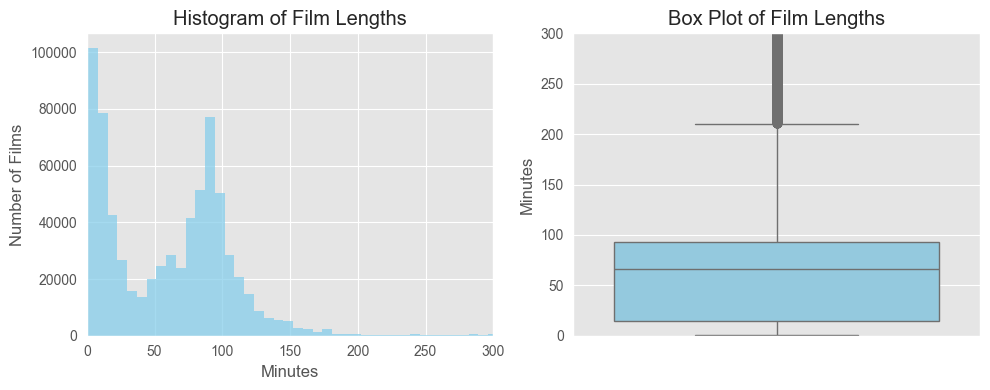

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(movies_df['minute'], bins=10000, kde=False, ax=axes[0], color='skyblue')
axes[0].set_title('Histogram of Film Lengths')
axes[0].set_xlabel('Minutes')
axes[0].set_ylabel('Number of Films')
axes[0].set_xlim(0, 300)

sns.boxplot(y=movies_df['minute'], ax=axes[1], color='skyblue')
axes[1].set_title('Box Plot of Film Lengths')
axes[1].set_ylabel('Minutes')
axes[1].set_ylim(0, 300)

plt.tight_layout()
plt.show()

COMMENTI FINALI

RATING FILM PRODOTTI DOPO IL 2000
function in pytho with jupyter notebook that creates a bar plot that shows the rating of films created after the 2000 . Tha rating is a float value that goes from 1 to 5. every bar should rapresent an unit

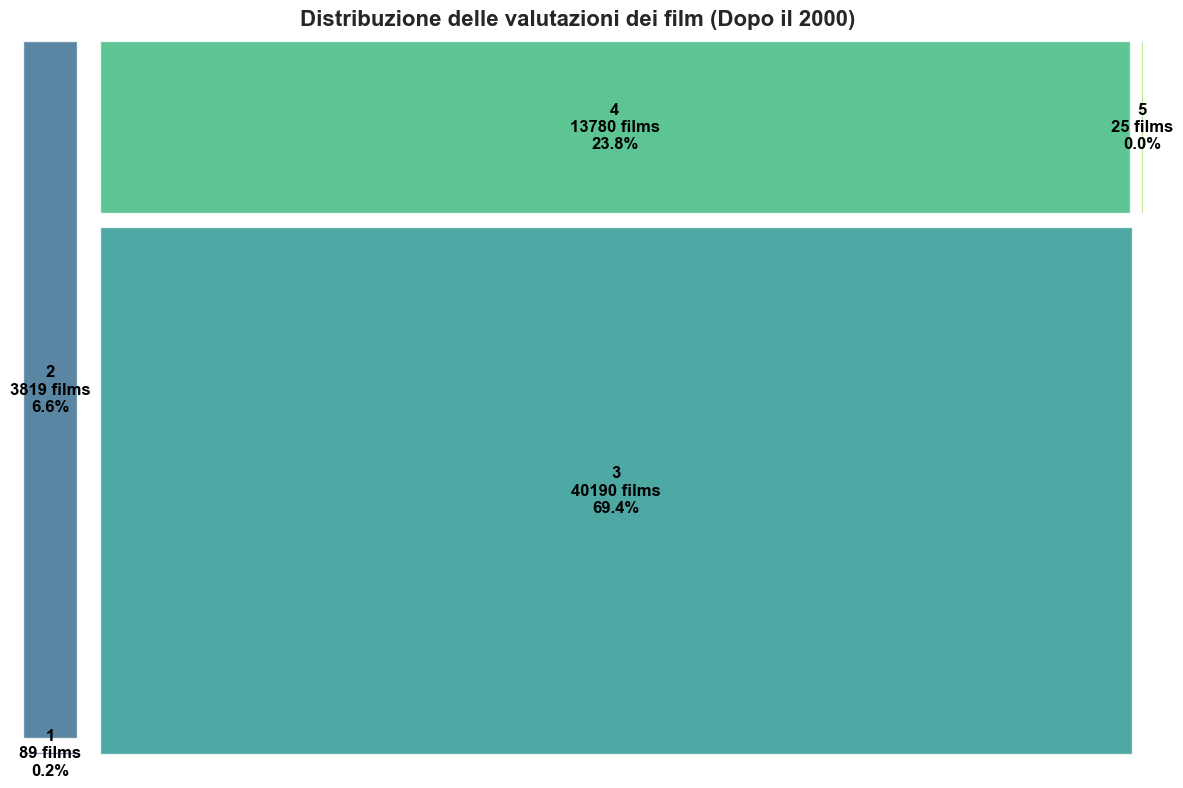

In [5]:
fun.movie_rating_century(movies_df)

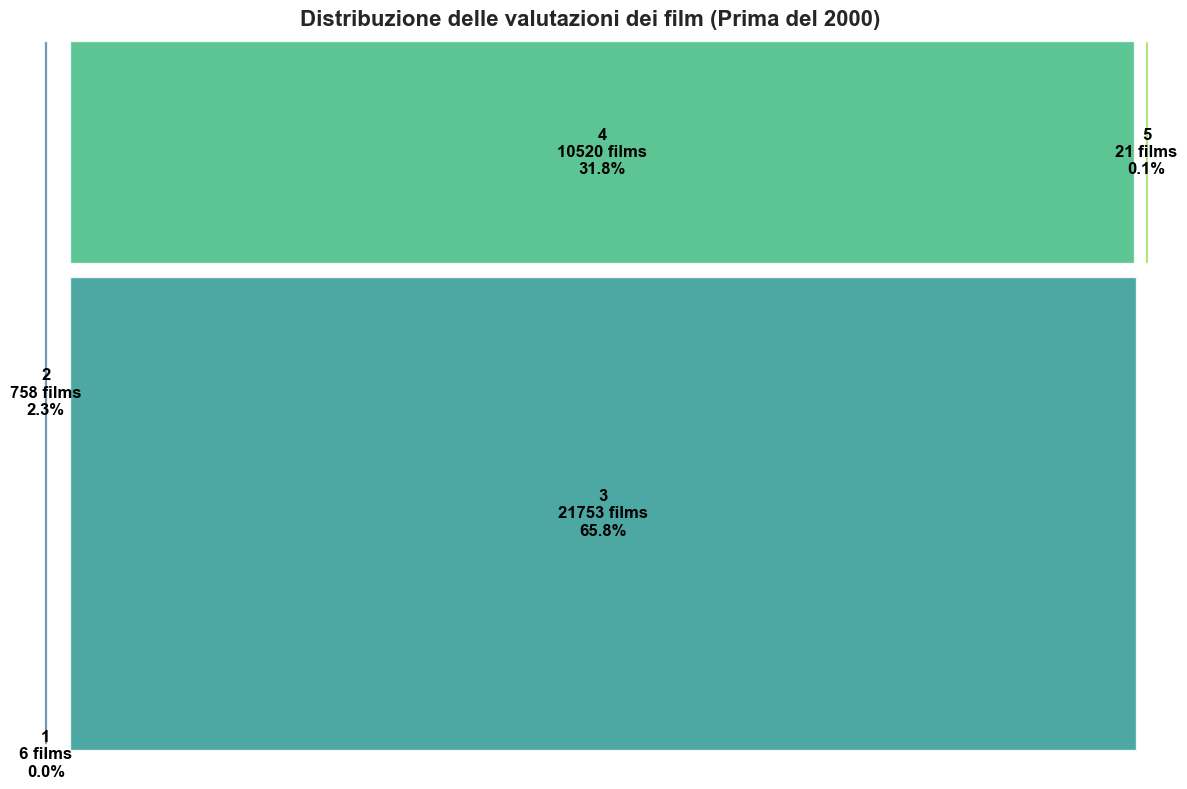

In [6]:
fun.movie_rating_century(movies_df, False)

Beh che dire, dopo il l'inizio del 21esimo secolo, nonostante la migliore tecnologia, abbiamo meno film con un rating maggiore di 4 punti compresi.

## Poster Trends

## Release Trends


### Most used kind of releases


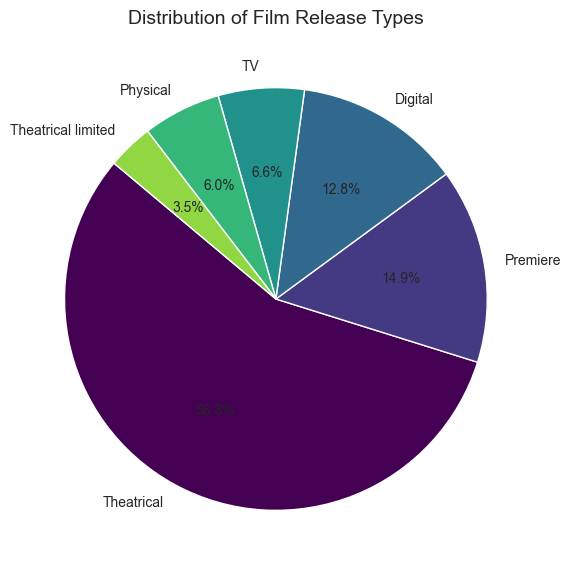

In [14]:
"""
This function creates a pie chart that shows the distribution of the most frequent
film release types in the 'releases_df' DataFrame.
"""

# Count the occurrences of each release type
release_counts = releases_df['type'].value_counts()

# Create the pie chart
plt.figure(figsize=(6, 6))
plt.pie(release_counts, labels=release_counts.index, autopct='%1.1f%%', startangle=140, colors=fun.color_palette(release_counts))

# Set the title
plt.title('Distribution of Film Release Types', fontsize=14)

# Adjust layout to add space between the chart and the title
plt.subplots_adjust(top=1.0)  # Reduce the top to add more space

# Display the pie chart
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

## ..


In [15]:
fun.plot_most_common_genre_theatrical(releases_df, genres_df)

AttributeError: module 'functions' has no attribute 'plot_most_common_genre_theatrical'

## Studio Trends

## Theme Trends